# Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

### Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

### Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency
import scipy.stats as stats

In [2]:
path = "C:/Users/ferna/OneDrive/Desktop/Fernando/Ironhack/DSML/Week_2/lab-eda-univariate/archive/amz_uk_price_prediction_dataset.csv"
raw_data = pd.read_csv(path)

In [3]:
df = raw_data.copy()

## Part 1: Analyzing Best-Seller Trends Across Product Categories
### Objective: Understand the relationship between product categories and their best-seller status.

### 1. Crosstab Analysis:

### - Create a crosstab between the product category and the isBestSeller status.

### - Are there categories where being a best-seller is more prevalent?

### Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

### 2. Statistical Tests:

### - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
### - Compute Cramér's V to understand the strength of association between best-seller status and category.

### 3. Visualizations:

### - Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.shape

(2443651, 9)

In [6]:
df.category.nunique()

296

In [7]:
df.category.value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [8]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [9]:
category_bestseller_ct = pd.crosstab( df["category"], df["isBestSeller"])

category_bestseller_ct.columns = ["Not Best Seller", "Best Seller"]

category_bestseller_ct

,Not Best Seller,Best Seller
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [10]:
category_bestseller_pct = pd.crosstab(df["category"], df["isBestSeller"], normalize="index") * 100

category_bestseller_pct.columns = ["Not Best Seller (%)", "Best Seller (%)"]
category_bestseller_pct = category_bestseller_pct.sort_values("Best Seller (%)", ascending=False)

category_bestseller_pct

,Not Best Seller (%),Best Seller (%)
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
...,...,...
"CD, Disc & Tape Players",100.000000,0.000000
General Music-Making Accessories,100.000000,0.000000
Snowboard Boots,100.000000,0.000000


In [11]:
top_10_category_bestseller_pct = category_bestseller_pct.head(10)

top_10_category_bestseller_pct

,Not Best Seller (%),Best Seller (%)
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
"Billiard, Snooker & Pool",96.787149,3.212851
Pet Supplies,96.979972,3.020028
Home Brewing & Wine Making,97.154472,2.845528
Wind Instruments,97.200000,2.800000


In [14]:
# 1. Create a contingency table (cross-tabulation)
contingency_table = pd.crosstab(df['isBestSeller'], df['category'])

# 2. Perform the Chi-square test
# chi2: The test statistic
# p: The p-value
# dof: Degrees of freedom
# expected: The expected frequencies under the null hypothesis
chi2, p, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square Statistic: {chi2:.3f}")
print(f"P-value: {p:.6f}")
print(f"Degrees of Freedom: {dof}")

# 3. Interpretation
alpha = 0.05
if p < alpha:
    print("Result: Reject the null hypothesis (There is a significant relationship between Category and BestSeller status).")
else:
    print("Result: Fail to reject the null hypothesis (No significant evidence of a relationship).")

Chi-square Statistic: 36540.203
P-value: 0.000000
Degrees of Freedom: 295
Result: Reject the null hypothesis (There is a significant relationship between Category and BestSeller status).


In [15]:
# 1. Prepare contingency table
contingency_table = pd.crosstab(df['isBestSeller'], df['category'])

# 2. Get Chi-square statistic
chi2, p, dof, expected = chi2_contingency(contingency_table)

# 3. Calculate Cramér's V
n = contingency_table.sum().sum()  # Total number of observations
min_dim = min(contingency_table.shape) - 1  # min(rows-1, cols-1)

cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1223


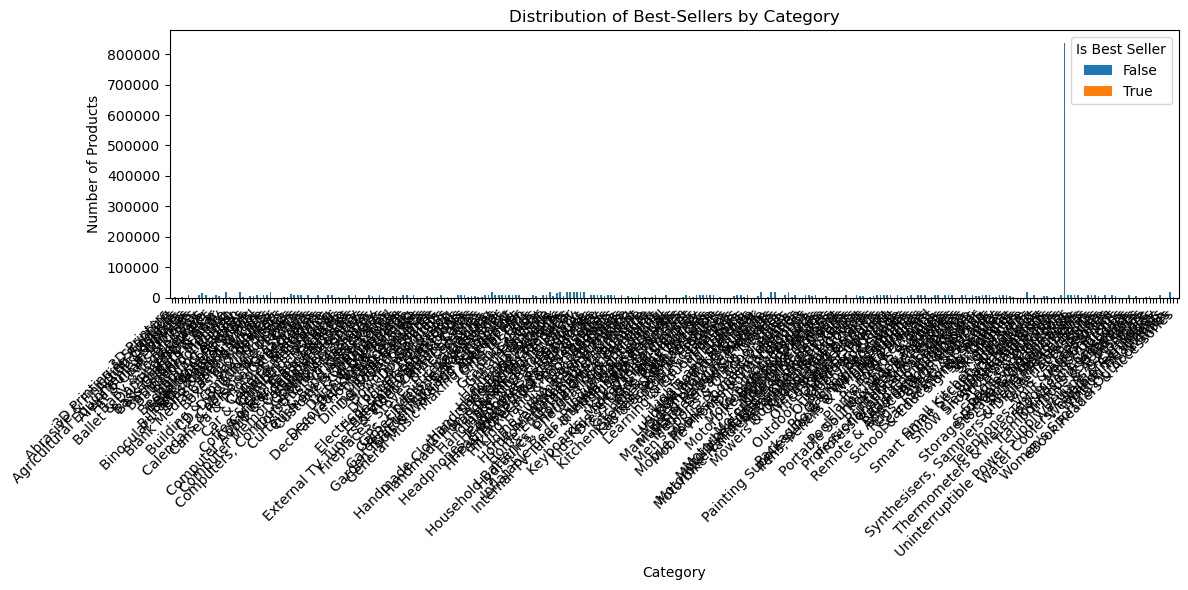

In [16]:
# 1. Create a contingency table (counts of True/False best-sellers per category)
ct = pd.crosstab(df['category'], df['isBestSeller'])

# 2. Plot the stacked bar chart
# The crosstab automatically uses the categories as the x-axis index
ct.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.title("Distribution of Best-Sellers by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right') # Rotate labels for readability
plt.legend(title='Is Best Seller')
plt.tight_layout()

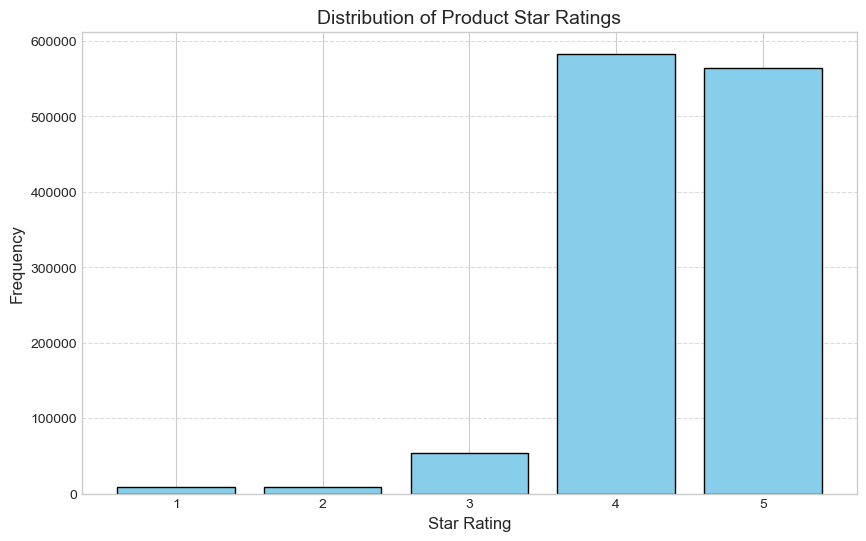

In [18]:
# Use a cleaner style
plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(10, 6))
# Using 'rwidth' and 'edgecolor' makes the bars distinct
plt.hist(df["stars"], bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5], 
         color='skyblue', edgecolor='black', rwidth=0.8)

plt.xlabel("Star Rating", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Distribution of Product Star Ratings", fontsize=14)
plt.xticks([1, 2, 3, 4, 5])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
### Objective: Investigate how different product categories influence product prices.

### Preliminary Step: Remove outliers in product prices.

### For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

### Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

### 1. Violin Plots:

### - Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
### - Which product category tends to have the highest median price? Don't filter here by top categories.

### 2. Bar Charts:

### - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
### - Which product category commands the highest average price? Don't filter here by top categories.

### 3. Box Plots:

### - Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
### - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [20]:
# Calculate IQR for the price column
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create the filtered dataframe (df_clean)
df_clean = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_clean.shape}")

Original shape: (2443651, 9)
Cleaned shape: (2115963, 9)


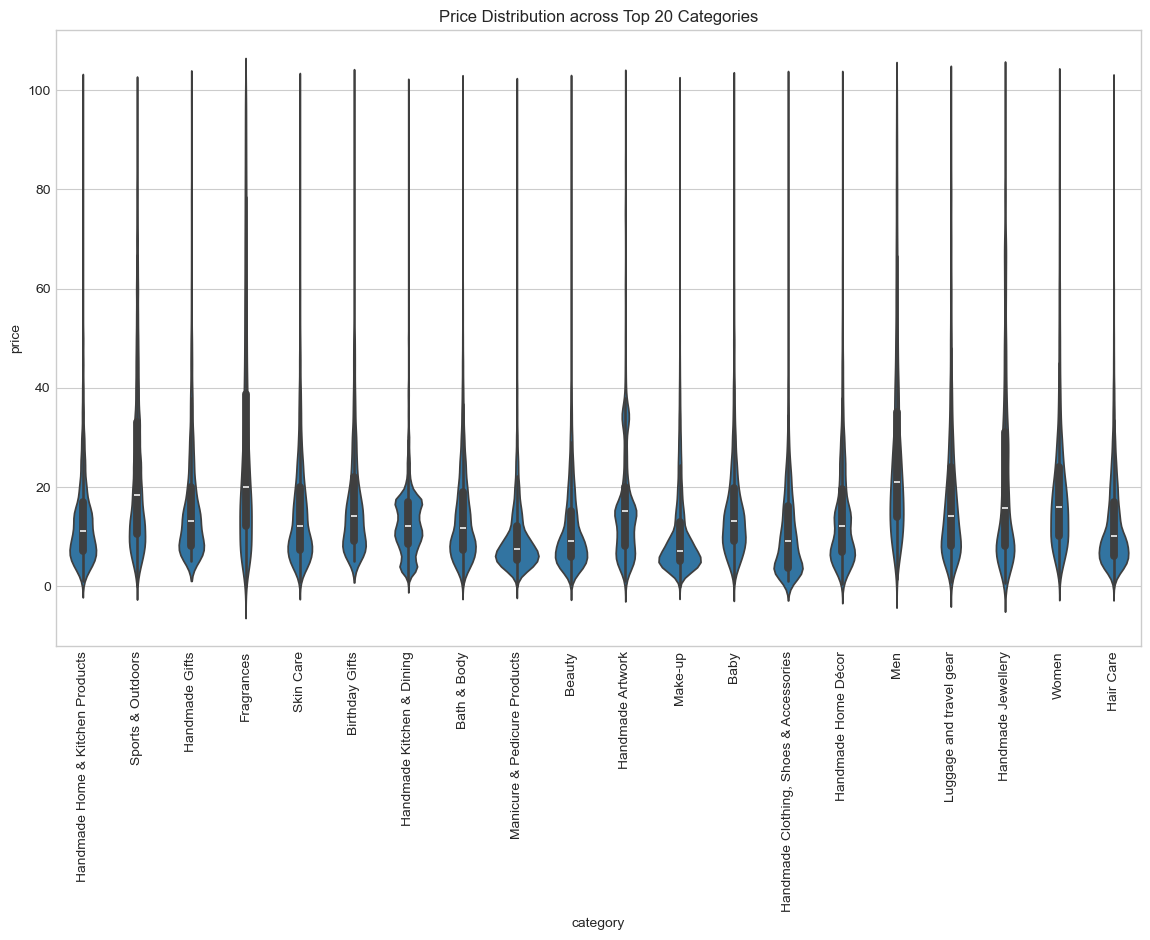

Category with the highest median price: Desktop PCs


In [21]:
# Get top 20 categories by count
top_20_cats = df_clean["category"].value_counts().nlargest(20).index
df_top20 = df_clean[df_clean["category"].isin(top_20_cats)]

# Visualization for Top 20 categories
plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top20, x="category", y="price")
plt.xticks(rotation=90)
plt.title("Price Distribution across Top 20 Categories")
plt.show()

# Find category with the highest median price (using full dataset)
median_prices = df_clean.groupby("category")["price"].median()
highest_median_cat = median_prices.idxmax()
print(f"Category with the highest median price: {highest_median_cat}")

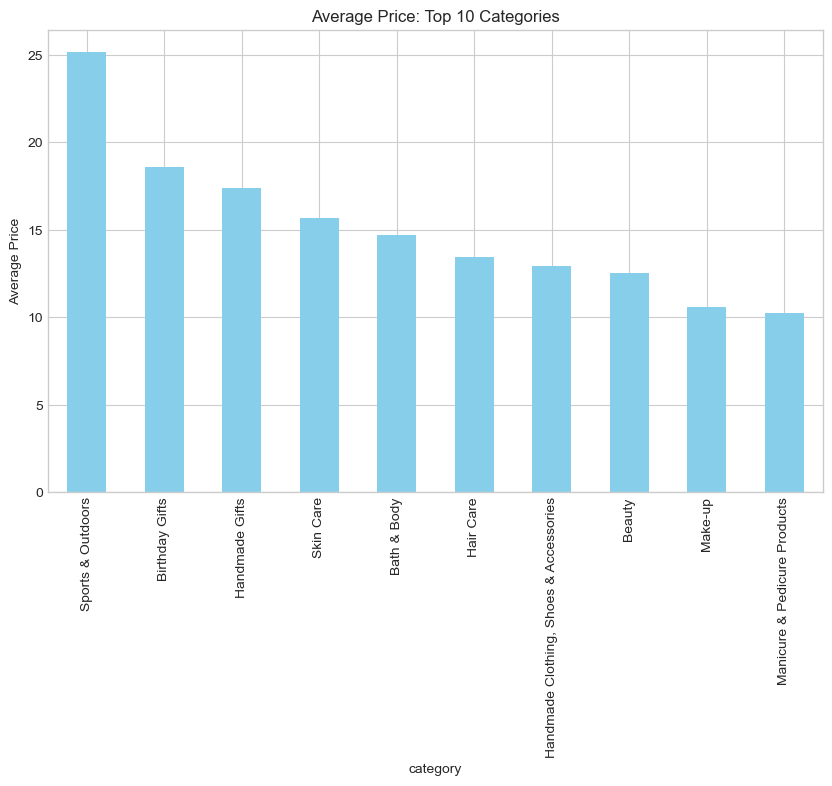

Category with the highest average price: Motherboards


In [22]:
# Create bar chart for top 10 categories by count
top_10_cats = df_clean["category"].value_counts().nlargest(10).index
df_top10 = df_clean[df_clean["category"].isin(top_10_cats)]

avg_price_top10 = df_top10.groupby("category")["price"].mean().sort_values(ascending=False)
avg_price_top10.plot(kind='bar', figsize=(10, 6), color='skyblue')
plt.title("Average Price: Top 10 Categories")
plt.ylabel("Average Price")
plt.show()

# Category with highest average price (full dataset)
highest_avg_cat = df_clean.groupby("category")["price"].mean().idxmax()
print(f"Category with the highest average price: {highest_avg_cat}")

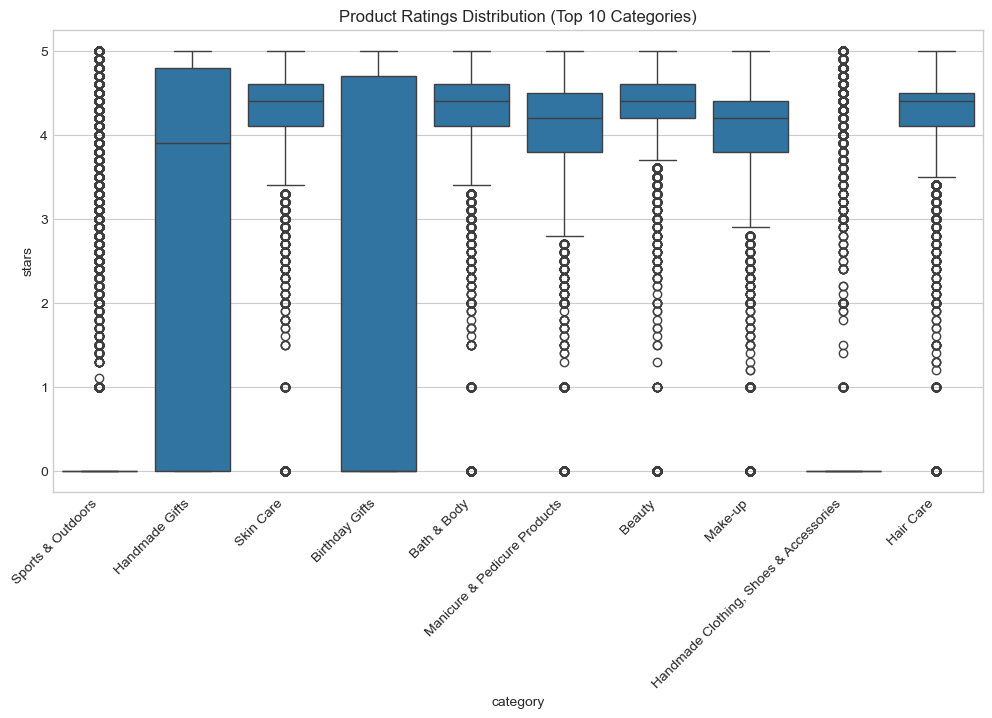

Category with the highest median rating: Computer Memory


In [23]:
# Visualize top 10 categories by count
df_top10_ratings = df_clean[df_clean["category"].isin(top_10_cats)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10_ratings, x="category", y="stars")
plt.xticks(rotation=45, ha='right')
plt.title("Product Ratings Distribution (Top 10 Categories)")
plt.show()

# Find category with highest median rating (full dataset)
median_ratings = df_clean.groupby("category")["stars"].median()
highest_median_rating_cat = median_ratings.idxmax()
print(f"Category with the highest median rating: {highest_median_rating_cat}")

## Part 3: Investigating the Interplay Between Product Prices and Ratings
#### Objective: Analyze how product ratings (stars) correlate with product prices.

### 1. Correlation Coefficients:

### - Calculate the correlation coefficient between price and stars.
### - Is there a significant correlation between product price and its rating?

### 2. Visualizations:

### - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
### - Use a correlation heatmap to visualize correlations between all numerical variables.
### - Examine if product prices typically follow a normal distribution using a QQ plot.

In [24]:
# Calculate Pearson correlation
correlation = df_clean["stars"].corr(df_clean["price"])
print(f"Correlation coefficient between Price and Stars: {correlation:.4f}")

Correlation coefficient between Price and Stars: -0.0777


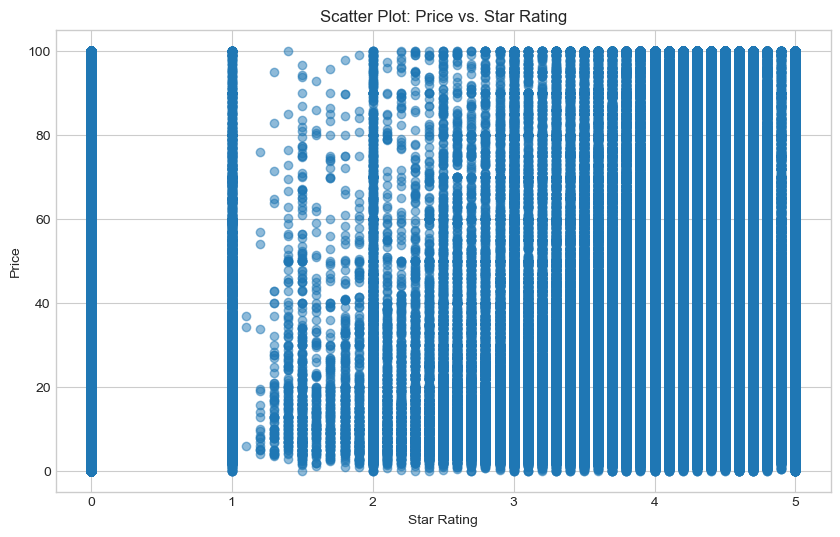

In [25]:
plt.figure(figsize=(10, 6))
plt.scatter(df_clean["stars"], df_clean["price"], alpha=0.5)
plt.xlabel("Star Rating")
plt.ylabel("Price")
plt.title("Scatter Plot: Price vs. Star Rating")
plt.show()

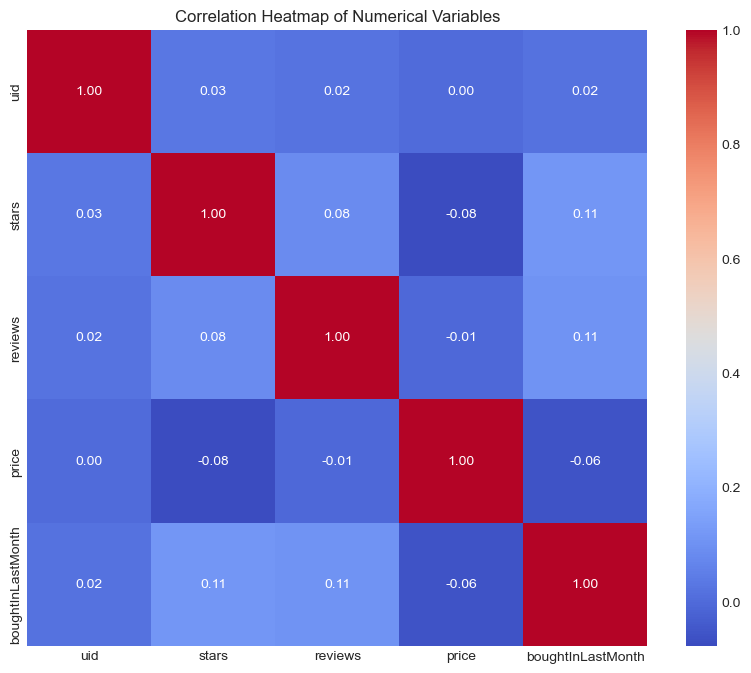

In [26]:
# Select numerical columns
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df_clean[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

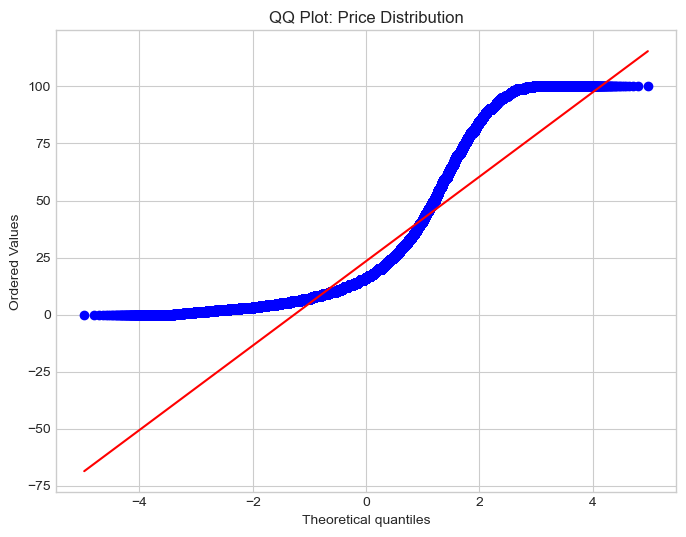

In [29]:
plt.figure(figsize=(8, 6))
stats.probplot(df_clean["price"], dist="norm", plot=plt)
plt.title("QQ Plot: Price Distribution")
plt.show()